# 💧 İstanbul Barajları Keşifsel Veri Analizi (EDA) ve İstatistiksel Modelleme

Bu Jupyter Notebook; İstanbul'daki **10 ana baraj havzasının** yağış verilerini (`2011–2024`), genel baraj doluluk oranlarını (`2005–2021`) ve günlük su tüketim eğilimlerini istatistiksel olarak inceler.

### İçindekiler
1. **Veri Setlerinin Yüklenmesi ve Genel Bakış**
2. **Baraj Havzaları Yağış İstatistikleri (2011–2024)**
3. **Coğrafi Havza Kümelemesi ve Korelasyon Analizi**
4. **Kritik Kuraklık Dönemleri (<%30 Doluluk Eşiği) Analizi**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')

df_occ = pd.read_csv('../dam_occupancy.csv', parse_dates=['DATE'])
df_merged = pd.read_csv('../data/istanbul_baraj_birlesik_veri.csv', parse_dates=['Tarih'])
df_unpivot = pd.read_csv('../data/istanbul_baraj_yagis_unpivot.csv', parse_dates=['Tarih'])

print(f'Baraj Doluluk Verisi (2005-2021): {df_occ.shape[0]:,} gün')
print(f'Birleşik Yağış & Tüketim Verisi (2011-2024): {df_merged.shape[0]:,} gün')
df_merged.head(5)

Baraj Doluluk Verisi (2005-2021): 5,941 gün
Birleşik Yağış & Tüketim Verisi (2011-2024): 4,797 gün


,Tarih,Ömerli,Darlık,Elmalı,Terkos,Büyükçekmece,Sazlıdere,Alibey,Kazandere,Pabuçdere,Istrancalar,Gunluk_Tuketim_m3,Toplam_Yagis_mm,Ortalama_Yagis_mm,Doluluk_Orani_Yuzde,Rezerv_Su_Milyon_m3,Yil,Ay,Mevsim
0,2011-01-01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2096199,0.00,0.00,83.85,728.0,2011,1,Kış
1,2011-01-02,0.00,0.00,0.00,0.42,1.37,0.87,0.20,2.26,1.89,1.39,2214668,8.40,0.84,83.80,728.0,2011,1,Kış
2,2011-01-03,8.08,10.01,11.64,18.82,9.64,14.72,13.50,8.20,10.37,16.47,2092441,121.45,12.14,83.76,728.0,2011,1,Kış
3,2011-01-04,2.78,8.48,7.09,3.42,0.83,4.31,4.30,1.44,1.60,3.99,2096199,38.24,3.82,83.96,729.0,2011,1,Kış
4,2011-01-05,0.00,0.78,0.00,0.42,0.00,0.00,0.56,1.15,1.11,0.80,2214668,4.82,0.48,84.50,734.0,2011,1,Kış


## 1. Baraj Havzaları Yağış İstatistikleri (2011–2024)
Aşağıdaki tablo 10 baraj havzasının günlük ortalama, maksimum, yağışlı gün oranı (`>0.1 mm`) ve kümülatif yağış miktarlarını göstermektedir:

In [2]:
barajlar = ['Ömerli', 'Darlık', 'Elmalı', 'Terkos', 'Büyükçekmece', 'Sazlıdere', 'Alibey', 'Kazandere', 'Pabuçdere', 'Istrancalar']

ozet_tablo = pd.DataFrame({
    'Toplam Yağış (mm)': df_merged[barajlar].sum().round(1),
    'Yıllık Ort. Yağış (mm/yıl)': (df_merged[barajlar].sum() / (len(df_merged) / 365.25)).round(1),
    'Günlük Ort. (mm)': df_merged[barajlar].mean().round(2),
    'Maksimum Günlük (mm)': df_merged[barajlar].max().round(2),
    'Yağışlı Gün Oranı (%)': ((df_merged[barajlar] > 0.1).mean() * 100).round(1)
}).sort_values('Toplam Yağış (mm)', ascending=False)

ozet_tablo

,Toplam Yağış (mm),Yıllık Ort. Yağış (mm/yıl),Günlük Ort. (mm),Maksimum Günlük (mm),Yağışlı Gün Oranı (%)
Kazandere,12469.7,949.5,2.60,170.20,27.4
Pabuçdere,11746.5,894.4,2.45,171.08,26.9
Istrancalar,11646.1,886.7,2.43,172.00,30.3
Terkos,11563.7,880.5,2.41,131.28,31.6
Darlık,10883.0,828.6,2.27,82.69,32.3
Ömerli,9952.1,757.8,2.07,123.53,29.8
Alibey,9682.3,737.2,2.02,119.00,30.1
Elmalı,9045.6,688.7,1.89,95.47,30.7
Sazlıdere,8734.2,665.0,1.82,178.25,27.9
Büyükçekmece,8057.2,613.5,1.68,95.59,27.3


## 2. Coğrafi Havza Kümelemesi (Korelasyon Analizi)
İstanbul baraj havzaları coğrafi konumlarına göre 3 belirgin yağış rejimi kümesi oluşturmaktadır:
- **Kuzeybatı Karadeniz Kuşağı (Kazandere, Pabuçdere, Istrancalar):** En yüksek yağışı alan ve kendi aralarında  > 0.84$ korelasyona sahip havzalar.
- **Anadolu Yakası Havzaları (Ömerli, Darlık, Elmalı):** Kendi aralarında  \in [0.76, 0.82]$ korelasyon gösteren havzalar.
- **Avrupa Yakası İç Havzaları (Büyükçekmece, Sazlıdere, Alibey):** Kendi aralarında  \in [0.74, 0.80]$ korelasyon gösteren havzalar.

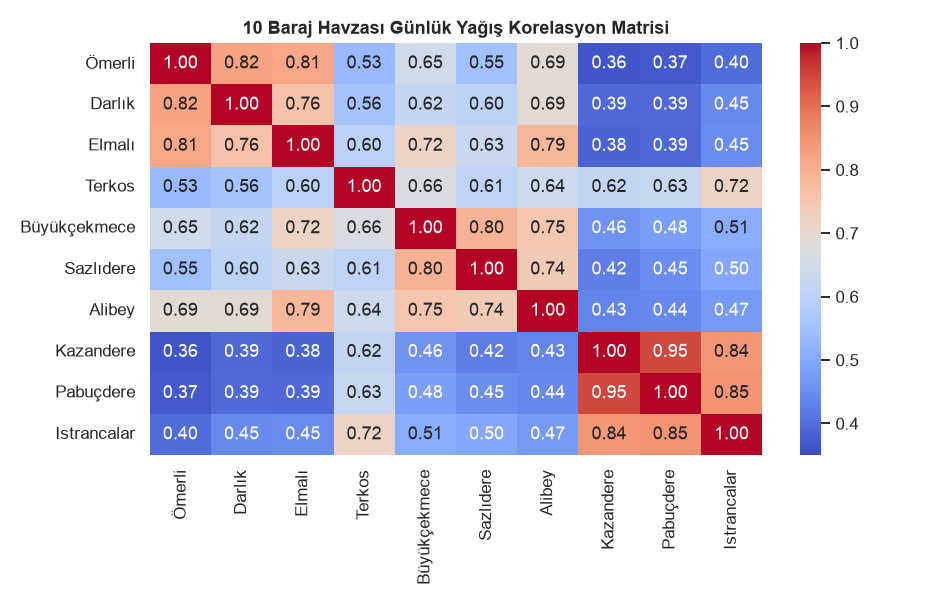

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=110)
corr = df_merged[barajlar].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=0.35, vmax=1.0, ax=ax)
ax.set_title('10 Baraj Havzası Günlük Yağış Korelasyon Matrisi', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Kritik Kuraklık Dönemleri (<%30 Doluluk Eşiği)
2005–2021 yılları arasında baraj doluluk oranının **%30 kritik eşiğinin** altına düştüğü dönemlerin istatistiksel dağılımı:

In [4]:
df_occ['Yil'] = df_occ['DATE'].dt.year
kurak_gunler = df_occ[df_occ['GENERAL_DAM_OCCUPANCY_RATE'] < 30]
kurak_ozet = kurak_gunler.groupby('Yil').agg(
    Kritik_Gun_Sayisi=('DATE', 'count'),
    Min_Doluluk_Yuzde=('GENERAL_DAM_OCCUPANCY_RATE', 'min'),
    Min_Rezerv_Milyon_m3=('GENERAL_DAM_RESERVED_WATER', 'min')
).sort_values('Kritik_Gun_Sayisi', ascending=False)

print(f'Toplam Kritik Kurak Gün Sayısı (<%30): {len(kurak_gunler)} gün (Tüm dönemin %{len(kurak_gunler)/len(df_occ)*100:.1f} oranı)')
kurak_ozet

Toplam Kritik Kurak Gün Sayısı (<%30): 638 gün (Tüm dönemin %10.7 oranı)


,Kritik_Gun_Sayisi,Min_Doluluk_Yuzde,Min_Rezerv_Milyon_m3
Yil,,,
2008,210,15.72,137
2014,192,14.46,126
2007,159,9.20,80
2020,60,20.29,176
2021,17,19.16,166
